In [12]:
import pandas as pd 
import numpy as numpy
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

df =pd.read_csv(r'C:\Users\mahagera.kisika\Desktop\data_science_project\Churn_Modelling.csv')
df.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [13]:
df.drop('CustomerId', axis=1, inplace=True)

C:\Users\mahagera.kisika\AppData\Local\Temp\ipykernel_6096\1431219765.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop('CustomerId', axis=1, inplace=True)


In [14]:
df.head(1)

,RowNumber,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,Hargrave,619,France,Female,42,2,0.0,1,1,1,101348.88,1


In [15]:
df.drop(['RowNumber', 'Surname'], axis=1, inplace=True)

C:\Users\mahagera.kisika\AppData\Local\Temp\ipykernel_6096\938948130.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(['RowNumber', 'Surname'], axis=1, inplace=True)


In [16]:
df['Gender'].value_counts()

Gender
Male      5457
Female    4543
Name: count, dtype: int64

In [17]:
from sklearn.preprocessing  import LabelEncoder
gender_incoder = LabelEncoder() 
df['Gender'] =gender_incoder.fit_transform(df['Gender'])

In [18]:
df.head(1)

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,619,France,0,42,2,0.0,1,1,1,101348.88,1


In [19]:
from sklearn.preprocessing import OneHotEncoder

one_hot_encoder = OneHotEncoder(sparse_output=False)
geo_one_hot = one_hot_encoder.fit_transform(df[['Geography']])
geo_one_hot

array([[1., 0., 0.],
       [0., 0., 1.],
       [1., 0., 0.],
       ...,
       [1., 0., 0.],
       [0., 1., 0.],
       [1., 0., 0.]], shape=(10000, 3))

In [20]:
one_hot_encoder.get_feature_names_out(['Geography'])

array(['Geography_France', 'Geography_Germany', 'Geography_Spain'],
      dtype=object)

In [21]:
geo_data_df=pd.DataFrame(geo_one_hot, columns=one_hot_encoder.get_feature_names_out(['Geography']))
geo_data_df

,Geography_France,Geography_Germany,Geography_Spain
0,1.0,0.0,0.0
1,0.0,0.0,1.0
2,1.0,0.0,0.0
3,1.0,0.0,0.0
4,0.0,0.0,1.0
...,...,...,...
9995,1.0,0.0,0.0
9996,1.0,0.0,0.0
9997,1.0,0.0,0.0
9998,0.0,1.0,0.0


In [22]:
df=pd.concat([df.drop('Geography', axis=1), geo_data_df], axis=1)

In [23]:
df.head()

,CreditScore,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Geography_France,Geography_Germany,Geography_Spain
0,619,0,42,2,0.00,1,1,1,101348.88,1,1.0,0.0,0.0
1,608,0,41,1,83807.86,1,0,1,112542.58,0,0.0,0.0,1.0
2,502,0,42,8,159660.80,3,1,0,113931.57,1,1.0,0.0,0.0
3,699,0,39,1,0.00,2,0,0,93826.63,0,1.0,0.0,0.0
4,850,0,43,2,125510.82,1,1,1,79084.10,0,0.0,0.0,1.0


In [24]:
import pickle

with open('gender_incoder.pkl', 'wb') as file:
    pickle.dump( gender_incoder,  file=file)

with open('one_hot_encoder.pkl', 'wb')   as file:
    pickle.dump( one_hot_encoder,  file=file) 

In [25]:
X=df.drop('Exited', axis=1)
y=df['Exited']

In [26]:
from sklearn.preprocessing import StandardScaler

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
scaler = StandardScaler()

X_train =scaler.fit_transform(X_train)
X_test= scaler.transform(X_test)


In [27]:
print(X_train)
print(X_test)

[[ 0.35649971  0.91324755 -0.6557859  ...  1.00150113 -0.57946723
  -0.57638802]
 [-0.20389777  0.91324755  0.29493847 ... -0.99850112  1.72572313
  -0.57638802]
 [-0.96147213  0.91324755 -1.41636539 ... -0.99850112 -0.57946723
   1.73494238]
 ...
 [ 0.86500853 -1.09499335 -0.08535128 ...  1.00150113 -0.57946723
  -0.57638802]
 [ 0.15932282  0.91324755  0.3900109  ...  1.00150113 -0.57946723
  -0.57638802]
 [ 0.47065475  0.91324755  1.15059039 ... -0.99850112  1.72572313
  -0.57638802]]
[[-0.57749609  0.91324755 -0.6557859  ... -0.99850112  1.72572313
  -0.57638802]
 [-0.29729735  0.91324755  0.3900109  ...  1.00150113 -0.57946723
  -0.57638802]
 [-0.52560743 -1.09499335  0.48508334 ... -0.99850112 -0.57946723
   1.73494238]
 ...
 [ 0.81311987 -1.09499335  0.77030065 ...  1.00150113 -0.57946723
  -0.57638802]
 [ 0.41876609  0.91324755 -0.94100321 ...  1.00150113 -0.57946723
  -0.57638802]
 [-0.24540869  0.91324755  0.00972116 ... -0.99850112  1.72572313
  -0.57638802]]


In [28]:
print(X_train.shape)
print(X_test.shape)

(8000, 12)
(2000, 12)


In [29]:
with open('scaler.pkl', 'wb') as file:
    pickle.dump(scaler, file=file)

In [30]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.callbacks import EarlyStopping, TensorBoard
import datetime

In [31]:
models = Sequential([
    Dense(64, activation='relu', input_shape=(X_train.shape[1],)),
    Dense(32, activation='relu'),
    Dense(16, activation='relu'),
    Dense(1, activation='sigmoid')
])

c:\Users\mahagera.kisika\Desktop\data_science_project\.venv\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [32]:
models.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │           832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,457 (13.50 KB)

 Trainable params: 3,457 (13.50 KB)

 Non-trainable params: 0 (0.00 B)

In [33]:
import tensorflow
opt = tensorflow.keras.optimizers.Adam(learning_rate=0.01)
loss= tensorflow.keras.losses.CategoricalFocalCrossentropy()
print(opt)
print(loss)

<LossFunctionWrapper(<function categorical_focal_crossentropy at 0x00000170810BBE20>, kwargs={'alpha': 0.25, 'gamma': 2.0, 'from_logits': False, 'label_smoothing': 0.0, 'axis': -1})>


In [34]:
models.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

In [35]:
from   tensorflow.keras.callbacks   import EarlyStopping, TensorBoard

log_dir ="log/fit" + datetime.datetime.now().strftime("%Y%m%d-%H%M%S")
tensorflow_callback = TensorBoard(log_dir=log_dir, histogram_freq=1)

In [36]:
EarlyStopping_callback = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)

In [37]:
history = models.fit(X_train, y_train, verbose=1,
                     validation_data=(X_test, y_test), 
                     epochs=100,    callbacks=[tensorflow_callback, EarlyStopping_callback])

Epoch 1/100
250/250 ━━━━━━━━━━━━━━━━━━━━ 35s 62ms/step - accuracy: 0.8043 - loss: 0.4486 - val_accuracy: 0.8445 - val_loss: 0.3819
Epoch 2/100
250/250 ━━━━━━━━━━━━━━━━━━━━ 5s 18ms/step - accuracy: 0.8496 - loss: 0.3651 - val_accuracy: 0.8545 - val_loss: 0.3434
Epoch 3/100
250/250 ━━━━━━━━━━━━━━━━━━━━ 5s 18ms/step - accuracy: 0.8600 - loss: 0.3436 - val_accuracy: 0.8660 - val_loss: 0.3435
Epoch 4/100
250/250 ━━━━━━━━━━━━━━━━━━━━ 4s 16ms/step - accuracy: 0.8605 - loss: 0.3383 - val_accuracy: 0.8600 - val_loss: 0.3391
Epoch 5/100
250/250 ━━━━━━━━━━━━━━━━━━━━ 5s 18ms/step - accuracy: 0.8631 - loss: 0.3320 - val_accuracy: 0.8610 - val_loss: 0.3521
Epoch 6/100
250/250 ━━━━━━━━━━━━━━━━━━━━ 4s 16ms/step - accuracy: 0.8666 - loss: 0.3296 - val_accuracy: 0.8545 - val_loss: 0.3520
Epoch 7/100
250/250 ━━━━━━━━━━━━━━━━━━━━ 5s 18ms/step - accuracy: 0.8643 - loss: 0.3272 - val_accuracy: 0.8605 - val_loss: 0.3381
Epoch 8/100
250/250 ━━━━━━━━━━━━━━━━━━━━ 9s 35ms/step - accuracy: 0.8675 - loss: 0.3236 -

In [38]:
models.save('models.h5')

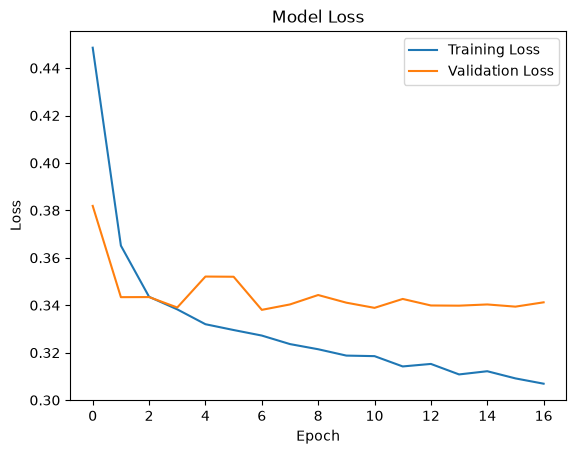

In [39]:
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend(['Training Loss', 'Validation Loss'])
plt.show()